# Concession extraction from specials text

Phase 2 step 2.1. Pulls the concession amount, its basis and the lease term out of the
advertised free text, and scores the result against `truth.concession`.

**Project step:** plan 2.3, docs/project_phases.md step 2.1.

**Inputs:** `data/accolade.duckdb` (`market.concession_event`, `truth.concession`).
Not the master table: it keeps only the first special per listing, while the source
holds all 91,156 and carries `text_style` and `text_source`.

**Outputs:** `outputs/01_phase_02_concession_extraction_summary.csv`,
`outputs/01_phase_02_concession_extraction_rows.csv`,
`outputs/01_phase_02_concession_accuracy_by_source.png`.

**Runtime:** ~10 s.

## What is actually being modelled

**Type is not a task.** `market.concession_event.type` already agrees with
`truth.concession.type` on **100%** of rows. A text classifier for concession type scores
about 1.0 by reading the column sitting next to the text. It is reported as a check, never
as a result.

**The value is the task.** The amount, its basis (months free or dollars) and the lease
term have to come out of the prose, and only `truth.concession` knows the answer.

In [1]:
# ---- Data ----
OUTPUT_DIR = "outputs"
LIMIT = None            # None = all 91,156 events; set an int to sample

# ---- Reporting ----
TOTAL_TOLERANCE = 0.05  # a concession's money value counts as right within +/- 5%
SHOW_MISSES = 10

In [2]:
from pathlib import Path
import sys

import pandas as pd

BLUE, GREEN, YELLOW, BOLD, RESET = "\033[94m", "\033[92m", "\033[93m", "\033[1m", "\033[0m"


def step(msg):
    print(f"\n{BOLD}{BLUE}\u25b6 {msg}{RESET}")


def done(msg):
    print(f"{GREEN}  \u2713 {msg}{RESET}")


def note(msg):
    print(f"{YELLOW}  \u2022 {msg}{RESET}")


ROOT = Path.cwd()
while not (ROOT / "data" / "master_listing.parquet").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUTPUTS = ROOT / OUTPUT_DIR
OUTPUTS.mkdir(parents=True, exist_ok=True)
NN, PHASE = 1, 2

# The rules live in preprocessing/extract_concessions.py so the same code backs
# this notebook and the command line.
sys.path.insert(0, str(ROOT / "preprocessing"))
import extract_concessions as ec


def out(name, ext="csv"):
    return OUTPUTS / f"{NN:02d}_phase_{PHASE:02d}_{name}.{ext}"

## Load and check the type claim

In [3]:
step("Reading concession events with their answer key")
events = ec.load(LIMIT)
done(f"{len(events):,} events")

agree = (events["observed_type"] == events["type"]).mean()
note(f"observed type matches the answer key on {100 * agree:.1f}% of rows "
     f"\u2014 type is given, not predicted")

generic = events["is_generic"].sum()
note(f"{generic:,} generic teasers ({100 * generic / len(events):.1f}%) state no terms "
     f'(for example "Specials available! Call for details.") and are excluded')
events["type"].value_counts().rename("events")


▶ Reading concession events with their answer key
  ✓ 91,156 events
  • observed type matches the answer key on 100.0% of rows — type is given, not predicted
  • 13,727 generic teasers (15.1%) state no terms (for example "Specials available! Call for details.") and are excluded


type
upfront_free_months    42670
one_time_credit        15464
unknown                13727
recurring_discount     11564
look_and_lease          7731
Name: events, dtype: int64

## Extract and score

`found_pct` is how often any amount came out. `basis_acc` is whether months-free versus
dollars matched. `amount_acc` requires both. `total_within_5pct` is the business number:
the money value of the concession, which is what feeds net effective rent.

In [4]:
step("Applying the extraction rules")
scored = ec.extract_frame(events)
real = scored[~scored["is_generic"]]
ev = ec.evaluate(real)
done(f"scored {len(ev):,} non-generic events")

overall = ec.summarize(ev)
print(overall.to_string(index=False))
ev[["basis_ok", "amount_ok", "term_ok", "total_ok"]].mean().mul(100).round(1).rename("pct")


▶ Applying the extraction rules


  ✓ scored 77,429 non-generic events
slice     n  found_pct  basis_acc  amount_acc  term_acc  total_within_5pct  total_median_pct_err
  all 77429       99.2       94.2        93.0      75.9               91.8                   0.0


basis_ok     94.2
amount_ok    93.0
term_ok      75.9
total_ok     91.8
Name: pct, dtype: float64

## By text style and generator

`docs/project_phases.md` cautions that the texts were written by an LLM, so rules risk
fitting that phrasing rather than English. The breakdown shows the caution is real but
points the other way: the LLM texts are the **easy** case, and the grammar fallback is
where the rules break.

In [5]:
frames = []
for by in ("type", "text_style", "text_source"):
    step(f"By {by}")
    t = ec.summarize(ev, by).sort_values("n", ascending=False)
    print(t.to_string(index=False))
    frames.append(t.rename(columns={by: "slice"}).assign(slice_by=by))

summary = pd.concat([overall.rename(columns={"slice": "slice"}).assign(slice_by="overall")] + frames,
                    ignore_index=True)
summary.to_csv(out("concession_extraction_summary"), index=False)
ev.drop(columns=["specials"]).to_csv(out("concession_extraction_rows"), index=False)
done(f"wrote {out('concession_extraction_summary').name} and the per-row file")
summary


▶ By type
               type     n  found_pct  basis_acc  amount_acc  term_acc  total_within_5pct  total_median_pct_err
upfront_free_months 42670       98.6       89.5        87.3      76.1               90.1                   0.0
    one_time_credit 15464      100.0      100.0       100.0      75.6              100.0                   0.0
 recurring_discount 11564      100.0      100.0       100.0      75.7               82.0                   0.0
     look_and_lease  7731      100.0      100.0       100.0      76.1              100.0                   0.0

▶ By text_style
text_style     n  found_pct  basis_acc  amount_acc  term_acc  total_within_5pct  total_median_pct_err
 marketing 31036       99.2       94.4        93.1      75.8               91.6                   0.0
     terse 27050       99.2       93.9        92.8      76.4               92.1                   0.0
  legalese 11623       99.3       93.8        92.5      75.7               91.6                   0.0
    bulle

  ✓ wrote 01_phase_02_concession_extraction_summary.csv and the per-row file


,slice,n,found_pct,basis_acc,amount_acc,term_acc,total_within_5pct,total_median_pct_err,slice_by
0,all,77429,99.2,94.2,93.0,75.9,91.8,0.0,overall
1,upfront_free_months,42670,98.6,89.5,87.3,76.1,90.1,0.0,type
2,one_time_credit,15464,100.0,100.0,100.0,75.6,100.0,0.0,type
3,recurring_discount,11564,100.0,100.0,100.0,75.7,82.0,0.0,type
4,look_and_lease,7731,100.0,100.0,100.0,76.1,100.0,0.0,type
5,marketing,31036,99.2,94.4,93.1,75.8,91.6,0.0,text_style
6,terse,27050,99.2,93.9,92.8,76.4,92.1,0.0,text_style
7,legalese,11623,99.3,93.8,92.5,75.7,91.6,0.0,text_style
8,bullet,7720,99.1,95.3,94.2,75.1,92.2,0.0,text_style
9,llm,69039,99.1,97.6,96.8,75.9,93.9,0.0,text_source


## Where the rules break

The weak cell is grammar-written `upfront_free_months`. It is not a phrasing problem: the
text quotes a **dollar** figure or a net effective rent while the answer key records the
concession in **months free**, so the units disagree even when the sentence is plain.
Recovering months from those needs the gross rent, which the text does not always give.

In [6]:
step("Accuracy of the weakest cell")
cell = ev[(ev["text_source"] == "grammar") & (ev["type"] == "upfront_free_months")]
note(f"grammar x upfront_free_months: n={len(cell):,}, "
     f"amount accuracy {100 * cell['amount_ok'].mean():.1f}%")

print(f"\n{BOLD}Examples{RESET}")
for _, r in cell[~cell["amount_ok"]].head(SHOW_MISSES).iterrows():
    print(f"  truth {r['value_amount']} {r['value_basis']}  |  read {r['pred_amount']} {r['pred_basis']}")
    print(f"     {ec.norm(r['specials'])[:120]}")


▶ Accuracy of the weakest cell
  • grammar x upfront_free_months: n=6,466, amount accuracy 50.6%

Examples
  truth 2.0 months_free  |  read 2.25 months_free
     get 9 weeks of free rent on select homes (12-month lease). terms and conditions apply; see leasing office for details.
  truth 1.5 months_free  |  read 2490.0 dollars
     • $2,490 move-in credit on a 14-month lease • select units • new residents only
  truth 0.5 months_free  |  read 798.0 dollars
     $798 off your first month. offer valid on new leases only, subject to availability and credit approval; cannot be combin
  truth 1.0 months_free  |  read 1235.0 dollars
     don't miss out: now leasing from $1,235 net effective on select kilo homes (14-month lease)! select homes only.
  truth 2.0 months_free  |  read 2.25 months_free
     spring special: get 9 weeks of free rent on select homes.
  truth 2.0 months_free  |  read 1436.0 dollars
     $1,436/mo net effective (gross $1,675). hurry, offer ends soon!
  truth 1.5 month

## Accuracy by generator


▶ Plotting accuracy by text source


  ✓ wrote 01_phase_02_concession_accuracy_by_source.png


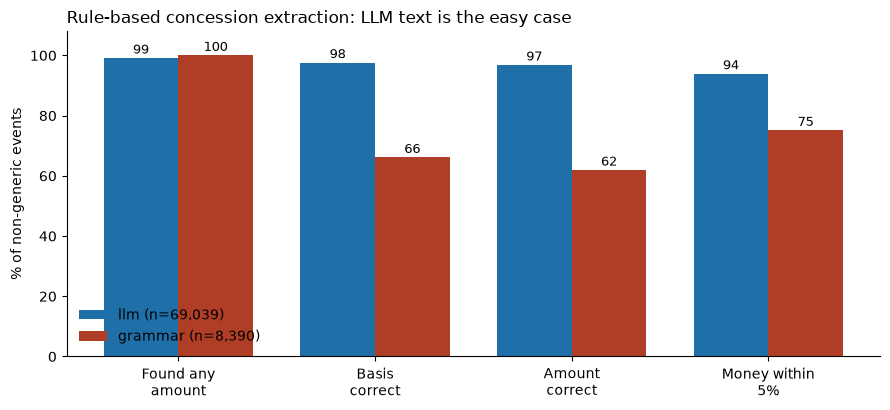

In [7]:
import matplotlib.pyplot as plt

step("Plotting accuracy by text source")
by_src = ec.summarize(ev, "text_source").set_index("text_source")
metrics = ["found_pct", "basis_acc", "amount_acc", "total_within_5pct"]
labels = ["Found any\namount", "Basis\ncorrect", "Amount\ncorrect", "Money within\n5%"]

fig, ax = plt.subplots(figsize=(9, 4.2))
x = range(len(metrics))
w = 0.38
for i, (src, color) in enumerate((("llm", "#1F6FA8"), ("grammar", "#B03E26"))):
    if src not in by_src.index:
        continue
    vals = [by_src.loc[src, m] for m in metrics]
    pos = [v + (i - 0.5) * w for v in x]
    ax.bar(pos, vals, width=w, color=color, label=f"{src} (n={by_src.loc[src, 'n']:,.0f})")
    for p, v in zip(pos, vals):
        ax.text(p, v + 1.5, f"{v:.0f}", ha="center", fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylim(0, 108)
ax.set_ylabel("% of non-generic events")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Rule-based concession extraction: LLM text is the easy case", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(out("concession_accuracy_by_source", "png"), dpi=150)
done(f"wrote {out('concession_accuracy_by_source', 'png').name}")
plt.show()